In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

## importacion de librerias

importamos las librerias que necesitamos para trabajar con los datos, aplicar el algoritmo dbscan y crear las graficas de los resultados.

In [2]:
df = pd.read_csv('comportamiento_jugadores.csv')
df.head()

,Metrica_X,Metrica_Y,Escenario,Descripcion_Ejes
0,44.125085,74.436148,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
1,19.905609,115.313604,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
2,55.833550,119.616643,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
3,10.243052,129.259511,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
4,5.413660,259.896958,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD


## carga del dataset

cargamos el archivo comportamiento_jugadores.csv utilizando pandas. tambien revisamos los primeros registros para conocer como estan organizados los datos.

In [3]:
df['Escenario'].value_counts()

Escenario
1_Economia_Juego       600
2_Deteccion_Hackers    600
3_Estilos_Batalla      600
Name: count, dtype: int64

## identificacion de escenarios

revisamos cuantos registros pertenecen a cada escenario. esto nos permite confirmar que el dataset contiene los tres escenarios que vamos a analizar por separado.

In [4]:
escenarios = df['Escenario'].unique()
resultados = {}

for escenario in escenarios:

    print("\nEscenario:", escenario)

    df_filtrado = df[df['Escenario'] == escenario].copy()

    X_crudo = df_filtrado[['Metrica_X', 'Metrica_Y']]

    scaler = StandardScaler()
    X_escalado = scaler.fit_transform(X_crudo)

    #dbscan implementado
    modelo = DBSCAN(eps=0.25, min_samples=5)

    #creacion de los clusters : entrenando al modelo
    clusters = modelo.fit_predict(X_escalado)

    df_filtrado['Cluster'] = clusters
    resultados[escenario] = df_filtrado

    print("cantidad de jugadores:", len(df_filtrado))
    print("clusters encontrados:",
          len(set(clusters) - {-1}))
    print("jugadores ruido:",
          list(clusters).count(-1))


Escenario: 1_Economia_Juego
cantidad de jugadores: 600
clusters encontrados: 3
jugadores ruido: 3

Escenario: 2_Deteccion_Hackers
cantidad de jugadores: 600
clusters encontrados: 2
jugadores ruido: 2

Escenario: 3_Estilos_Batalla
cantidad de jugadores: 600
clusters encontrados: 2
jugadores ruido: 0


## aplicacion de dbscan 

separamos los datos utilizando la columna escenario y extraemos las metricas x y y de cada uno.

despues aplicamos standardscaler para que ambas metricas tengan la misma importancia al calcular las distancias.

finalmente, ejecutamos dbscan utilizando eps de 0.25 y min_samples de 5 para identificar los grupos de jugadores y los puntos considerados como ruido.

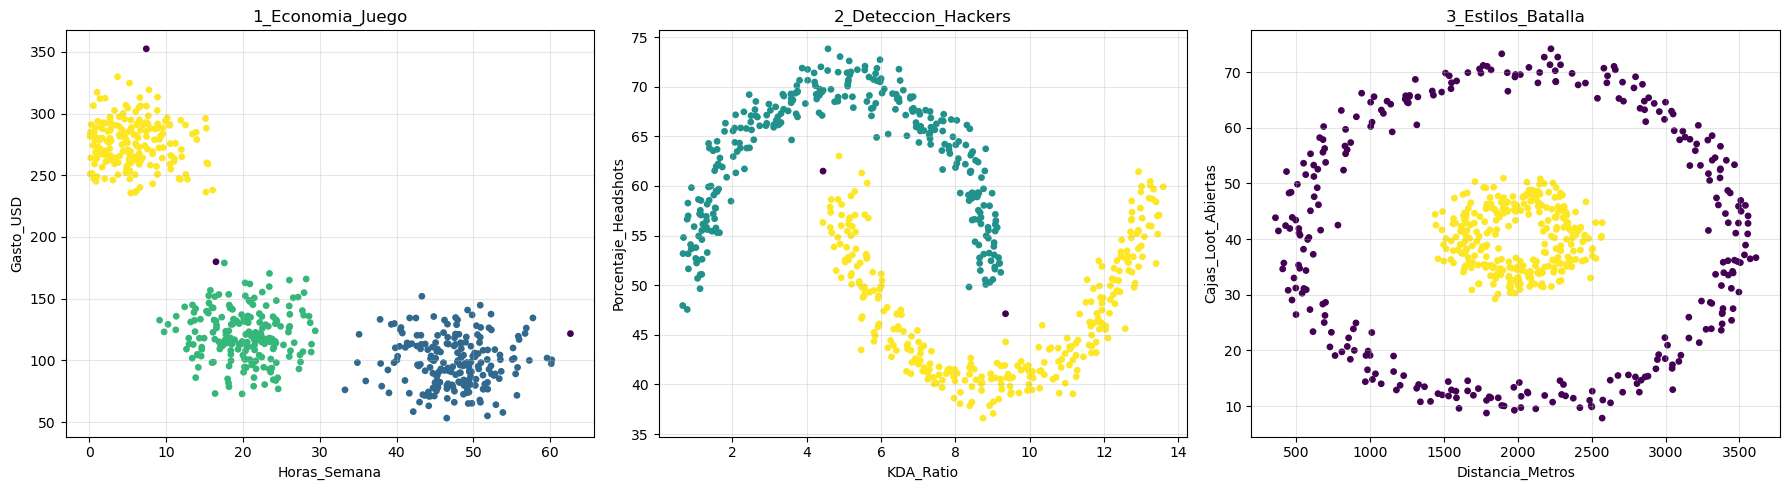

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (escenario, datos) in zip(axes, resultados.items()):

    scatter = ax.scatter(
        datos['Metrica_X'],
        datos['Metrica_Y'],
        c=datos['Cluster'],
        cmap='viridis',
        s=15
    )

    ax.set_title(escenario)
    ax.set_xlabel(datos['Descripcion_Ejes'].iloc[0].split('|')[0].replace('X:', '').strip())
    ax.set_ylabel(datos['Descripcion_Ejes'].iloc[0].split('|')[1].replace('Y:', '').strip())

    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## visualizacion de los resultados

creamos tres graficas de dispersion para observar como dbscan agrupo a los jugadores en cada escenario.

cada punto representa un jugador y los colores representan los grupos identificados. los puntos clasificados como ruido tienen la etiqueta -1.

## analisis de resultados

comparamos los grupos encontrados y la cantidad de puntos considerados como ruido en cada escenario.

esto nos permite observar como se comporta dbscan con diferentes tipos de datos y que tan bien logra identificar grupos de jugadores.

## conclusion

dbscan nos permitio identificar grupos de jugadores con comportamientos similares sin tener que indicar previamente la cantidad de grupos.

sin embargo, observamos que sus resultados dependen de los parametros eps y min_samples. elegir una distancia inadecuada puede provocar que los grupos se dividan o que varios puntos sean clasificados como ruido.